In [39]:
import os
import ast
import json
import random
import torch
import numpy as np
import pandas as pd
from PIL import Image
from collections import defaultdict
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from sklearn.model_selection import train_test_split

In [64]:
CSV_PATH = "archive/metadata.csv"
IMAGE_DIR = "archive/photo" 
BATCH_SIZE = 32
LEARNING_RATE = 0.001
EPOCHS = 100
TEST_SPLIT_RATIO = 0.33
TISSUE_TYPE = "NAIL"   # or "SKIN"
FINGER_INDEX = 1       # Specific finger index or None for random
IMG_SIZE = 64          # SimpleCNN uses 64x64
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [56]:
class HandImageDataset(Dataset):
    def __init__(self, metadata_df, image_folder, tissue_type="NAIL", finger_index=None, image_size=(64, 64)):
        self.image_folder = image_folder
        self.image_data = dict()
        self.metadata = metadata_df
        self.patient_ids = list(metadata_df["PATIENT_ID"])
        self.tissue_type = tissue_type
        self.finger_index = finger_index

        self.transform = T.Compose([
            T.Resize(image_size),
            T.ToTensor(),
        ])
        
        print("Loading and cropping images into memory...")
        for _, row in self.metadata.iterrows():
            patient_id = row["PATIENT_ID"]
            img_path = os.path.join(self.image_folder, f"{patient_id}.jpg")
            
            try:
                img = Image.open(img_path).convert("RGB")
            except FileNotFoundError:
                # Add this print statement to see the wrong path
                print(f"Missing image! Looked here: {img_path}") 
                continue
            
            nails_bboxes = json.loads(row["NAIL_BOUNDING_BOXES"]) if isinstance(row["NAIL_BOUNDING_BOXES"], str) else row["NAIL_BOUNDING_BOXES"]
            skin_bboxes = json.loads(row["SKIN_BOUNDING_BOXES"]) if isinstance(row["SKIN_BOUNDING_BOXES"], str) else row["SKIN_BOUNDING_BOXES"]

            self.image_data[patient_id] = defaultdict(list)
            
            for tissue, bboxes in zip(["NAIL", "SKIN"], [nails_bboxes, skin_bboxes]):
                for (top, left, bot, right) in bboxes:
                    selected_region = img.crop((left, top, right, bot))
                    self.image_data[patient_id][tissue].append(selected_region)
            
            self.image_data[patient_id]["target"] = row["HB_LEVEL_GperL"]

        self.patient_ids = [pid for pid in self.patient_ids if pid in self.image_data]

    def __len__(self):
        return len(self.patient_ids)

    def __getitem__(self, index):
        patient_id = self.patient_ids[index]
        image_data = self.image_data[patient_id]
        tissue_regions = image_data[self.tissue_type]

        if self.finger_index is not None and (0 <= self.finger_index < len(tissue_regions)):
            selected_image = tissue_regions[self.finger_index]
        else:
            selected_image = random.choice(tissue_regions)

        selected_image = self.transform(selected_image)
        target = image_data["target"]

        return selected_image, torch.tensor(target, dtype=torch.float32)

In [57]:
class SimpleCNN(torch.nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = torch.nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1) 
        self.conv2 = torch.nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.pool = torch.nn.MaxPool2d(kernel_size=2, stride=2)
        # 64x64 image -> pooled twice -> 16x16
        self.fc1 = torch.nn.Linear(64 * 16 * 16, 128)
        self.fc2 = torch.nn.Linear(128, 1)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x))) 
        x = self.pool(torch.relu(self.conv2(x))) 
        x = x.view(x.size(0), -1) # Flatten
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [ ]:
def train_and_validate():
    # 1. Load metadata
    metadata = pd.read_csv(CSV_PATH).dropna(subset=['HB_LEVEL_GperL', 'NAIL_BOUNDING_BOXES'])
    print(f"Total rows in metadata: {len(metadata)}")
    print(f"Looking for images in: {os.path.abspath(IMAGE_DIR)}")
    
    # 2. Train/Test Split
    train_indices, test_indices = train_test_split(np.arange(len(metadata)), test_size=TEST_SPLIT_RATIO, random_state=42)
    
    # 3. Initialize Datasets
    train_dataset = HandImageDataset(metadata.iloc[train_indices], IMAGE_DIR, tissue_type=TISSUE_TYPE, finger_index=FINGER_INDEX)
    test_dataset = HandImageDataset(metadata.iloc[test_indices], IMAGE_DIR, tissue_type=TISSUE_TYPE, finger_index=FINGER_INDEX)
    
    # 4. Critical Diagnostic Check
    print(f"Train dataset length: {len(train_dataset)}")
    print(f"Test dataset length: {len(test_dataset)}")
    
    if len(train_dataset) == 0:
        raise RuntimeError(f"CRITICAL: Train dataset is empty. Check if images exist in {os.path.abspath(IMAGE_DIR)}")
    
    train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    test_dataloader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

    # 5. Training Loop
    model = SimpleCNN().to(DEVICE)
    criterion = torch.nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    print(f"Starting training on {DEVICE}...")
    for epoch in range(EPOCHS):
        model.train()
        train_loss = 0.0
        for images, targets in train_dataloader:
            images, targets = images.to(DEVICE), targets.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs.squeeze(), targets)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
        
        train_loss /= len(train_dataloader)

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for images, targets in test_dataloader:
                images, targets = images.to(DEVICE), targets.to(DEVICE)
                outputs = model(images)
                loss = criterion(outputs.squeeze(), targets)
                val_loss += loss.item()
                
        val_loss /= len(test_dataloader)
        
        print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")
        
    return model

In [59]:
def export_and_save(model, base_name="anemia_simplecnn_edge"):
    model.eval().cpu()
    
    # 1. Save PyTorch weights
    weights_path = f"{base_name}.pth"
    torch.save(model.state_dict(), weights_path)
    print(f"Saved PyTorch weights to {weights_path}")
    
    # 2. Export standard FP32 ONNX
    onnx_path = f"{base_name}.onnx"
    dummy_input = torch.randn(1, 3, IMG_SIZE, IMG_SIZE) # Note: 64x64 input
    
    torch.onnx.export(
        model, 
        dummy_input, 
        onnx_path,
        export_params=True, 
        dynamo=True,          
        input_names=['input'], 
        output_names=['hb_level']
    )
    print(f"Successfully exported FP32 ONNX edge model to {onnx_path}")

if __name__ == "__main__":
    trained_model = train_and_validate()
    export_and_save(trained_model)

Total rows in metadata: 250
Looking for images in: /home/td/Doc/Prog/Ai|Ml/project/anemia_prediction/archive/photo
Loading and cropping images into memory...
Loading and cropping images into memory...
Train dataset length: 167
Test dataset length: 83
Starting training on cpu...
Epoch 1/100 | Train Loss: 14895.3156 | Val Loss: 8529.9673
Epoch 2/100 | Train Loss: 3436.7666 | Val Loss: 6119.6379
Epoch 3/100 | Train Loss: 2665.0973 | Val Loss: 1755.1692
Epoch 4/100 | Train Loss: 2264.6287 | Val Loss: 1971.5326
Epoch 5/100 | Train Loss: 1152.6941 | Val Loss: 1637.0702
Epoch 6/100 | Train Loss: 1315.0458 | Val Loss: 1228.6238
Epoch 7/100 | Train Loss: 1108.0551 | Val Loss: 1355.6059
Epoch 8/100 | Train Loss: 1117.9763 | Val Loss: 1227.0406
Epoch 9/100 | Train Loss: 1028.9557 | Val Loss: 1187.0394
Epoch 10/100 | Train Loss: 999.7100 | Val Loss: 1185.0913
Epoch 11/100 | Train Loss: 861.8734 | Val Loss: 1259.0362
Epoch 12/100 | Train Loss: 929.7437 | Val Loss: 1169.5565
Epoch 13/100 | Train Los

W0701 23:10:19.317000 1929914 site-packages/torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0701 23:10:19.318000 1929914 site-packages/torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'rois' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0701 23:10:19.319000 1929914 site-packages/torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0). Treating as an Input.
W0701 23:10:19.320000 1929914 site-packages/torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'boxes' from (input, boxes, output_size: 'Sequence[int

[torch.onnx] Obtain model graph for `SimpleCNN([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `SimpleCNN([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decomposition...
[torch.onnx] Run decomposition... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
Successfully exported FP32 ONNX edge model to anemia_simplecnn_edge.onnx


Predicted Hb: 116.00 g/L


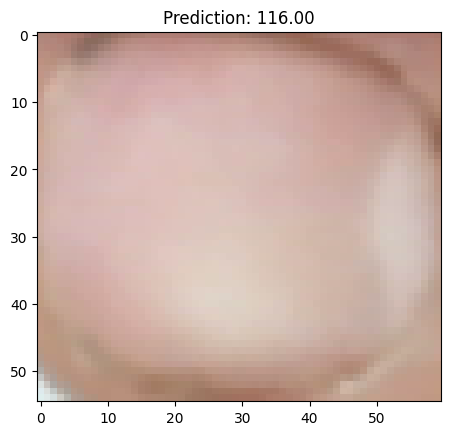

In [66]:
import torch
import pandas as pd
from PIL import Image
import torchvision.transforms as T
import ast
import matplotlib.pyplot as plt

# 1. Define the exact same architecture used in training
class SimpleCNN(torch.nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = torch.nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1)
        self.conv2 = torch.nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.pool = torch.nn.MaxPool2d(kernel_size=2, stride=2)
        self.fc1 = torch.nn.Linear(64 * 16 * 16, 128)
        self.fc2 = torch.nn.Linear(128, 1)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# 2. Setup Inference
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = SimpleCNN().to(DEVICE)

# 3. Load the Weights
# Use map_location to ensure it loads even if saved on GPU
model.load_state_dict(torch.load("anemia_simplecnn_edge.pth", map_location=DEVICE, weights_only=True))
model.eval()

# 4. Helper to prepare image
transform = T.Compose([T.Resize((64, 64)), T.ToTensor()])

def predict_single_image(patient_id, bbox_str):
    # Use the full absolute path we identified earlier
    base_dir = "/home/td/Doc/Prog/Ai|Ml/project/anemia_prediction/archive/photo"
    img_path = f"{base_dir}/{patient_id}.jpg"
    
    img = Image.open(img_path).convert("RGB")
    
    # Crop based on metadata
    coords = ast.literal_eval(bbox_str)
    top, left, bot, right = coords[0]
    crop = img.crop((left, top, right, bot))
    
    # Predict
    input_tensor = transform(crop).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        prediction = model(input_tensor)
    return prediction.item(), crop

# 5. Execute Prediction
df = pd.read_csv("archive/metadata.csv")
sample = df.iloc[6] # Pick a patient
pred, crop = predict_single_image(sample['PATIENT_ID'], sample['NAIL_BOUNDING_BOXES'])

print(f"Predicted Hb: {pred:.2f} g/L")
plt.imshow(crop)
plt.title(f"Prediction: {pred:.2f}")
plt.show()